G_E_LIME Efforts

In [1]:
from sklearn.datasets import load_breast_cancer
import numpy as np
import lime
import pandas as pd
import numpy as np
import lime.lime_tabular
import warnings
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import sys
import os
import statistics

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y)
model = MLPClassifier()
model.fit(X_train, y_train)

feature_names = load_breast_cancer().feature_names
categorical_features = np.argwhere(np.array([len(set(X_train[:,x])) for x in range(X_train.shape[1])]) <=10).flatten()

explainer = lime.lime_tabular.LimeTabularExplainer(X_train, feature_names=feature_names, 
                                                categorical_features = categorical_features, verbose=True, mode='classification')

# Choose which instance to examine
input = 24

# Produce explanations for the instance
exp = explainer.explain_instance(X[input], model.predict_proba, num_features=5)

Intercept 0.4945064681706193
Prediction_local [-0.14536308]
Right: 1.9602726164771933e-18


In [3]:
import cufflinks as cf
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

In [4]:
# 125 MINUTES 
sample_size = 5
from lime import submodular_pick
sp_obj = submodular_pick.SubmodularPick(explainer, X, model.predict_proba, sample_size=sample_size, num_features=10, num_exps_desired=5)

Intercept 0.277783758346537
Prediction_local [0.50744127]
Right: 0.9713261656148439
Intercept 0.22648358610324126
Prediction_local [0.66786396]
Right: 0.881224317332528
Intercept 0.3263395557784784
Prediction_local [0.37295298]
Right: 0.9982143951310536
Intercept 0.5028440001004175
Prediction_local [1.13474747]
Right: 0.9990903062857884
Intercept 0.30125236699280944
Prediction_local [0.47281534]
Right: 0.9991776369297687


In [5]:
W_pick=pd.DataFrame([dict(this.as_list(this.available_labels()[0])) for this in sp_obj.sp_explanations]).fillna(0)

df = W_pick.mean(axis=0)
df = abs(df.head())

values = df.values.tolist()
features = df.index.to_list()

sum_list = []
for i in range(len(features)):
    sum_list.append(features[i]+", "+str(values[i]))

feature_names = load_breast_cancer().feature_names
sum_list

['mean area > 765.38, 0.08439891526362618',
 'worst area > 1041.75, 0.06791663414610585',
 'worst perimeter > 124.97, 0.005306757002391282',
 'area error > 43.24, 0.04207271146701934',
 'mean perimeter > 103.55, 0.02072526170509445']

In [213]:
# Extract LIME explanations
feature_importance = []
for i in range(len(sum_list)):
    for word in feature_names:
    # if a word from the features list is present in the explanation strings (1st element of the list) then grab it
        if word in sum_list[i]:
            # transfer the feature and its value to a 
            feature_importance.append("%s = " %word + str("{:.3f}".format(float(sum_list[i].split(",")[1]))))

In [214]:
feature_importance

['worst area = 0.237',
 'mean perimeter = 0.061',
 'mean area = 0.055',
 'mean texture = 0.007',
 'perimeter error = 0.015']

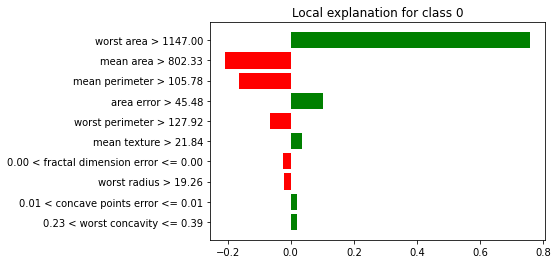

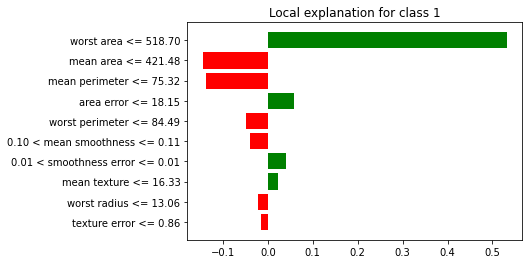

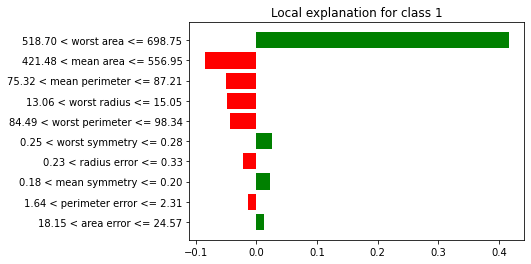

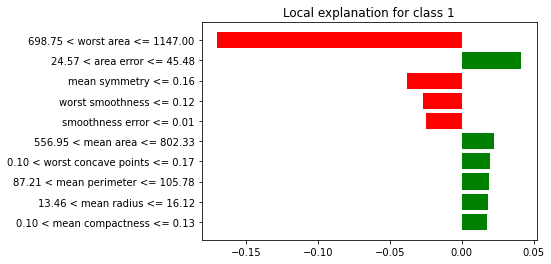

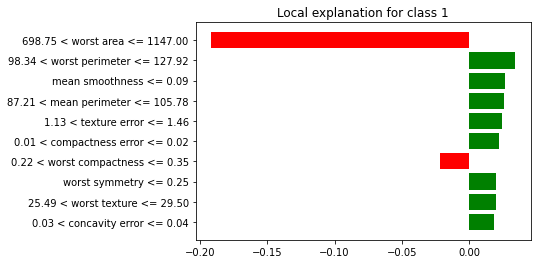

In [127]:
#Plot the 5 explanations
[exp.as_pyplot_figure(label=exp.available_labels()[0]) for exp in sp_obj.sp_explanations];
# Make it into a dataframe
W_pick=pd.DataFrame([dict(this.as_list(this.available_labels()[0])) for this in sp_obj.sp_explanations]).fillna(0)
 
W_pick['prediction'] = [this.available_labels()[0] for this in sp_obj.sp_explanations]
 
#Making a dataframe of all the explanations of sampled points
W=pd.DataFrame([dict(this.as_list(this.available_labels()[0])) for this in sp_obj.explanations]).fillna(0)
W['prediction'] = [this.available_labels()[0] for this in sp_obj.explanations]
 
#Plotting the aggregate importances
np.abs(W.drop("prediction", axis=1)).mean(axis=0).sort_values(ascending=False).head(20).sort_values(ascending=True).iplot(kind="barh")
 
#Aggregate importances split by classes
grped_coeff = W.groupby("prediction").mean()
 
grped_coeff = grped_coeff.T
grped_coeff["abs"] = np.abs(grped_coeff.iloc[:, 0])
grped_coeff.sort_values("abs", inplace=True, ascending=False)
grped_coeff.head(20).sort_values("abs", ascending=True).drop("abs", axis=1).iplot(
    kind="barh", bargap=0.5
)

In [269]:
with open(r'C:\Users\Stefanos Rigas\Documents\Projects\Thesis\thesis\robustness-evaluation\explanations\G_E_LIME\features.txt','r') as file:
    data = file.readlines()

file.close()

In [271]:
experiments = 10
values = []
features = []
for i in range(10):
    for j in range(5):
        x = data[i*8+j+2].split()
        values.append(x[3])
        features.append(x[0]+x[1])

IndexError: list index out of range

In [268]:
features

['worstarea',
 'meanarea',
 'worstperimeter',
 'meanperimeter',
 'areaerror',
 'meanarea',
 'worstarea',
 'meanperimeter',
 'worstperimeter',
 'meanradius',
 'worstarea',
 'meanarea',
 'areaerror',
 'worstperimeter',
 'meanperimeter',
 'worstarea',
 'meanarea',
 'worstperimeter',
 'meanperimeter',
 'areaerror',
 'worstarea',
 'meanperimeter',
 'meanarea',
 'meantexture',
 'worstperimeter',
 'worstarea',
 'meanarea',
 'worstperimeter',
 'meanperimeter',
 'areaerror',
 'worstarea',
 'meanarea',
 'worstperimeter',
 'compactnesserror',
 'radiuserror',
 'worstarea',
 'meanperimeter',
 'meanarea',
 'areaerror',
 'worstradius',
 'worstarea',
 'meanperimeter',
 'meanarea',
 'areaerror',
 'meanconcave',
 'worstarea',
 'meanarea',
 'areaerror',
 'worstperimeter',
 'meanperimeter']

In [251]:
# Make changes here on the dimensions of the dataframes for evaluating more experiments (here we have 5 features)
  
# Make dataframe with the weights of the features for each run  
values = np.array(values)
sub_arrays = np.hsplit(values, experiments)
df = pd.DataFrame(sub_arrays)
for i in range(experiments):
    df.index = ['Run_%d'%(i+1) for i in range(experiments)]
df.columns = ['1st Feature', '2nd Feature', '3rd Feature', '4th Feature', '5th Feature']

# Make dataframe with the feature names (ranking of the features at each experiment)
features = np.array(features)
sub_arrays2 = np.hsplit(features, experiments)
df2 = pd.DataFrame(sub_arrays2)
for i in range(experiments):
    df2.index = ['Run_%d'%(i+1) for i in range(experiments)]
df2.columns = ['1st Feature', '2nd Feature', '3rd Feature', '4th Feature', '5th Feature']
df2 = df2.applymap(lambda x: x.replace('=', ''))

In [252]:
# Gather here the unique features
uniqueValues = (df2['1st Feature'].append(df2['2nd Feature'].append(df2['3rd Feature'].append(df2['4th Feature'].append(df2['5th Feature']))))).unique()

df2 = df2.astype(str)
print("\nOur dataframes are:\n\n",df,"\n\n",df2,"\n")  
print("\nDescribe df with the feature names:\n\n", df2.describe())
print("\n..........................................\n")    


Our dataframes are:

        1st Feature 2nd Feature 3rd Feature 4th Feature 5th Feature
Run_1        0.249       0.098       0.045       0.026       0.014
Run_2        0.120       0.054       0.024       0.035       0.015
Run_3        0.031       0.026       0.043       0.020       0.012
Run_4        0.079       0.058       0.041       0.033       0.010
Run_5        0.167       0.108       0.093       0.036       0.025
Run_6        0.154       0.039       0.029       0.024       0.009
Run_7        0.226       0.133       0.037       0.005       0.002
Run_8        0.100       0.000       0.001       0.035       0.020
Run_9        0.140       0.073       0.024       0.016           =
Run_10       0.220       0.126       0.100       0.072       0.023 

        1st Feature    2nd Feature     3rd Feature       4th Feature  \
Run_1    worstarea       meanarea  worstperimeter     meanperimeter   
Run_2     meanarea      worstarea   meanperimeter    worstperimeter   
Run_3    worstarea      

In [253]:
for i in range(len(df.values)):
    for j in range(len(df.values[i])):
        try:
            float(df.values[i][j])
        except:
            df.values[i][j]=df.values[i-1][j] # take value of previous run if not a number

In [261]:
df1 = df.astype(float)
df1

,1st Feature,2nd Feature,3rd Feature,4th Feature,5th Feature
Run_1,0.249,0.098,0.045,0.026,0.014
Run_2,0.120,0.054,0.024,0.035,0.015
Run_3,0.031,0.026,0.043,0.020,0.012
Run_4,0.079,0.058,0.041,0.033,0.010
Run_5,0.167,0.108,0.093,0.036,0.025
Run_6,0.154,0.039,0.029,0.024,0.009
Run_7,0.226,0.133,0.037,0.005,0.002
Run_8,0.100,0.000,0.001,0.035,0.020
Run_9,0.140,0.073,0.024,0.016,0.020
Run_10,0.220,0.126,0.100,0.072,0.023


In [15]:
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=50000, n_features=30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y)
model = MLPClassifier()
model.fit(X_train, y_train)

z = pd.DataFrame(X)

feature_names = []
for i in z.columns:
    feature_names.append("Feature"+str(i))

categorical_features = np.argwhere(np.array([len(set(X_train[:,x])) for x in range(X_train.shape[1])]) <=10).flatten()

explainer = lime.lime_tabular.LimeTabularExplainer(X_train, feature_names=feature_names, 
                                                categorical_features = categorical_features, verbose=True, mode='classification')

# Choose which instance to examine
input = 24

# Produce explanations for the instance
exp = explainer.explain_instance(X[input], model.predict_proba, num_features=5)

c:\Users\Stefanos Rigas\AppData\Local\Programs\Python\Python38\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:692: ConvergenceWarning:

Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.



Intercept 0.732588696259754
Prediction_local [0.47495417]
Right: 0.053337602522678315


In [16]:
# 125 MINUTES 
sample_size = 5
from lime import submodular_pick
sp_obj = submodular_pick.SubmodularPick(explainer, X, model.predict_proba, sample_size=sample_size, num_features=10, num_exps_desired=5)

Intercept 0.5004035180706026
Prediction_local [1.12116169]
Right: 0.9999338642446391
Intercept 0.2725872290143511
Prediction_local [0.53126512]
Right: 0.9945478048017409
Intercept 0.5698548059895726
Prediction_local [0.98894298]
Right: 0.9798560280248331
Intercept 0.21964807121528243
Prediction_local [0.68719104]
Right: 0.9995712779302713
Intercept 0.4943169209506524
Prediction_local [1.15226328]
Right: 0.9994008133875613


In [17]:
W_pick=pd.DataFrame([dict(this.as_list(this.available_labels()[0])) for this in sp_obj.sp_explanations]).fillna(0)

df = W_pick.mean(axis=0)
df = abs(df.head())

values = df.values.tolist()
features = df.index.to_list()

sum_list = []
for i in range(len(features)):
    sum_list.append(features[i]+", "+str(values[i]))

In [18]:
sum_list

['Feature25 > 1.01, 0.15043752087722911',
 'Feature13 <= -0.73, 0.1792275351687184',
 'Feature27 <= -1.06, 0.04360281078349955',
 '-0.71 < Feature26 <= 0.08, 0.001297851403266316',
 'Feature22 <= -0.68, 0.004954963830528099']

In [21]:
# Extract LIME explanations
feature_importance = []
for i in range(len(sum_list)):
    for word in feature_names:
    # if a word from the features list is present in the explanation strings (1st element of the list) then grab it
        if word in sum_list[i]:
            # transfer the feature and its value to a 
            feature_importance.append("%s = " %word + str("{:.3f}".format(float(sum_list[i].split(",")[1]))))

In [38]:
with open(r'C:\Users\Stefanos Rigas\Documents\Projects\Thesis\thesis\robustness-evaluation\explanations\G_E_LIME\features.txt','r') as file:
    data = file.readlines()

file.close()